# I - DATA CLEANING SECTION

In this part we will clean data we found on kaggle directly before analysing them.
sources for the data :

source for data 1 (classification) : https://www.kaggle.com/datasets/aadarshvelu/aids-virus-infection-prediction?select=AIDS_Classification.csv

source for data 2 (Linear regression) : https://www.kaggle.com/datasets/rish59/financial-statements-of-major-companies2009-2023

# DATA CLEANING PART 1

In [1]:
#import library

import pandas as pd
import numpy as np

In [2]:
#import the first dataset

pd.set_option("display.max_columns", None)

data1 = pd.read_csv("dataset/AIDS_Classification.csv")
data1.head(10)

,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820,infected
0,948,2,48,89.8128,0,0,0,100,0,0,0,0,0,0,1,0,1,0,422,477,566,324,0
1,1002,3,61,49.4424,0,0,0,90,0,1,895,0,0,1,3,0,1,0,162,218,392,564,1
2,961,3,45,88.4520,0,1,1,90,0,1,707,0,1,1,3,0,1,1,326,274,2063,1893,0
3,1166,3,47,85.2768,0,1,0,100,0,1,1399,0,1,1,3,0,1,0,287,394,1590,966,0
4,1090,0,43,66.6792,0,1,0,100,0,1,1352,0,1,1,3,0,0,0,504,353,870,782,0
5,1181,1,46,88.9056,0,1,1,100,0,1,1181,0,1,1,3,0,1,0,235,339,860,1060,0
6,794,0,31,73.0296,0,1,0,100,0,1,930,0,1,1,3,0,0,0,244,225,708,699,1
7,957,0,41,66.2256,0,1,1,100,0,1,1329,0,1,1,3,0,0,0,401,366,889,720,0
8,198,3,40,82.5552,0,1,0,90,0,1,1074,0,1,1,3,1,1,1,214,107,652,131,1
9,188,0,35,78.0192,0,1,0,100,0,1,964,0,1,1,3,0,0,1,221,132,221,759,1


In [3]:
#seeing dimensions 

print(f"We have {data1.shape[0]} rows and {data1.shape[1]} columns")

We have 2139 rows and 23 columns


In [4]:
# look for single values in the columns

print(data1.nunique())

time         713
trt            4
age           59
wtkg         667
hemo           2
homo           2
drugs          2
karnof         4
oprior         2
z30            2
preanti      813
race           2
gender         2
str2           2
strat          3
symptom        2
treat          2
offtrt         2
cd40         484
cd420        570
cd80        1090
cd820       1050
infected       2
dtype: int64



#### UP THERE WE HAVE SOME SINGLE VALUES THAT REPEAT IN SOME TABLES BUT THE ARE GENERALLY BINARY OUTPUTS THE ARE REALLY IMPORTANT TO BUILD OUR LOGISTIC REGRESSION MODEL. SO WE ARE NOT DROPPING ANYTHING.


In [5]:
# Consider rows that have few single values 

for i in range(data1.shape[1]):
    num_unique = len(np.unique(data1.iloc[:, i]))
    percentage = (num_unique / data1.shape[0]) * 100
    print(f"Column {i}: {num_unique - 1} unique values ({percentage:.2f}%)")

Column 0: 712 unique values (33.33%)
Column 1: 3 unique values (0.19%)
Column 2: 58 unique values (2.76%)
Column 3: 666 unique values (31.18%)
Column 4: 1 unique values (0.09%)
Column 5: 1 unique values (0.09%)
Column 6: 1 unique values (0.09%)
Column 7: 3 unique values (0.19%)
Column 8: 1 unique values (0.09%)
Column 9: 1 unique values (0.09%)
Column 10: 812 unique values (38.01%)
Column 11: 1 unique values (0.09%)
Column 12: 1 unique values (0.09%)
Column 13: 1 unique values (0.09%)
Column 14: 2 unique values (0.14%)
Column 15: 1 unique values (0.09%)
Column 16: 1 unique values (0.09%)
Column 17: 1 unique values (0.09%)
Column 18: 483 unique values (22.63%)
Column 19: 569 unique values (26.65%)
Column 20: 1089 unique values (50.96%)
Column 21: 1049 unique values (49.09%)
Column 22: 1 unique values (0.09%)


In [6]:
# Looking for rows where the uning value porcentage are the lowest

for i in range(data1.shape[1]):
    num_unique = len(np.unique(data1.iloc[:, i]))
    percentage = (num_unique / data1.shape[0]) * 100
    if percentage < 1:
        print(f"Column {i}: {num_unique} unique values ({percentage:.2f}%)")

Column 1: 4 unique values (0.19%)
Column 4: 2 unique values (0.09%)
Column 5: 2 unique values (0.09%)
Column 6: 2 unique values (0.09%)
Column 7: 4 unique values (0.19%)
Column 8: 2 unique values (0.09%)
Column 9: 2 unique values (0.09%)
Column 11: 2 unique values (0.09%)
Column 12: 2 unique values (0.09%)
Column 13: 2 unique values (0.09%)
Column 14: 3 unique values (0.14%)
Column 15: 2 unique values (0.09%)
Column 16: 2 unique values (0.09%)
Column 17: 2 unique values (0.09%)
Column 22: 2 unique values (0.09%)


In [7]:
# lets check if there are any missing values

data1.info()

# All the rows are filled so there is no missing value

<class 'pandas.DataFrame'>
RangeIndex: 2139 entries, 0 to 2138
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   time      2139 non-null   int64  
 1   trt       2139 non-null   int64  
 2   age       2139 non-null   int64  
 3   wtkg      2139 non-null   float64
 4   hemo      2139 non-null   int64  
 5   homo      2139 non-null   int64  
 6   drugs     2139 non-null   int64  
 7   karnof    2139 non-null   int64  
 8   oprior    2139 non-null   int64  
 9   z30       2139 non-null   int64  
 10  preanti   2139 non-null   int64  
 11  race      2139 non-null   int64  
 12  gender    2139 non-null   int64  
 13  str2      2139 non-null   int64  
 14  strat     2139 non-null   int64  
 15  symptom   2139 non-null   int64  
 16  treat     2139 non-null   int64  
 17  offtrt    2139 non-null   int64  
 18  cd40      2139 non-null   int64  
 19  cd420     2139 non-null   int64  
 20  cd80      2139 non-null   int64  
 21  cd

In [8]:
duplicate_values = data1.duplicated()
print(duplicate_values)

0       False
1       False
2       False
3       False
4       False
        ...  
2134    False
2135    False
2136    False
2137    False
2138    False
Length: 2139, dtype: bool


In [9]:
if int(duplicate_values.any()) == 0 :
    print("there is no duplicated values")

there is no duplicated values


# DATA CLEANING PART 2

In [10]:
data2 = pd.read_csv("dataset/FinancialStatements.csv")
data2.head(10)

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,Cash Flow from Operating,Cash Flow from Investing,Cash Flow from Financial Activities,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US)
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.1100,130541.0,50672.0,122151.0,-22354.0,-110749.0,0.8794,2.3695,196.9589,28.2924,66.6994,25.3096,1.3146,196.9589,164000,8.0028
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.6100,120233.0,63090.0,104038.0,-14545.0,-93353.0,1.0746,1.9768,150.0713,26.9742,54.9839,25.8818,1.3261,150.0713,154000,4.6979
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.2800,77344.0,65339.0,80674.0,-4289.0,-86820.0,1.3636,1.7208,87.8664,17.7256,35.0054,20.9136,1.0183,87.8664,147000,1.2336
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.9700,76477.0,90488.0,69391.0,45896.0,-90976.0,1.5401,1.1940,61.0645,16.3230,30.3113,21.2381,-0.0388,61.0645,137000,1.8122
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.9800,81801.0,107147.0,77434.0,16066.0,-87876.0,1.1329,1.0685,55.5601,16.2775,29.6348,22.4142,0.7414,55.5601,132000,2.4426
5,2017,AAPL,IT,868.87,229234.0,88186.0,48351.0,2.3025,71501.0,134047.0,64225.0,-46446.0,-17974.0,1.2761,0.8630,36.0702,12.8826,20.9082,21.0924,0.0330,36.0702,123000,2.1301
6,2016,AAPL,IT,617.59,215639.0,84263.0,45687.0,2.0775,70529.0,128249.0,66231.0,-45977.0,-20890.0,1.3527,0.6786,35.6237,14.2024,22.4312,21.1868,-0.5901,38.1906,116000,1.2616
7,2015,AAPL,IT,586.86,233715.0,93626.0,53394.0,2.3050,82487.0,119355.0,81266.0,-56274.0,-17716.0,1.1088,0.5390,44.7355,18.3899,30.9201,22.8458,0.9743,48.3878,110000,0.1186
8,2014,AAPL,IT,647.36,182795.0,70537.0,39510.0,1.6125,60449.0,111547.0,59713.0,-22579.0,-37549.0,1.0801,0.3164,35.4201,17.0420,28.1142,21.6144,0.3032,38.4380,97000,1.6222
9,2013,AAPL,IT,504.79,170910.0,64304.0,37037.0,1.4200,55756.0,123549.0,53666.0,-33774.0,-16379.0,1.6786,0.1373,29.9776,17.8923,26.3592,21.6705,0.1363,31.4425,84400,1.4648


In [11]:
# Drop colums that seems useless to our model of prediction

data2 = pd.read_csv("dataset/FinancialStatements.csv")
drop = ["ROE", "ROA", "ROI", "Debt/Equity Ratio", 
        "EBITDA", "Share Holder Equity", "Return on Tangible Equity", 
        "Free Cash Flow per Share", "Cash Flow from Financial Activities", 
        "Cash Flow from Investing", "Cash Flow from Operating"]

data2 = data2.drop(drop, axis = 1)

data2

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,Current Ratio,Net Profit Margin,Number of Employees,Inflation Rate(in US)
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.1100,0.8794,25.3096,164000,8.0028
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.6100,1.0746,25.8818,154000,4.6979
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.2800,1.3636,20.9136,147000,1.2336
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.9700,1.5401,21.2381,137000,1.8122
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.9800,1.1329,22.4142,132000,2.4426
...,...,...,...,...,...,...,...,...,...,...,...,...
156,2013,AMZN,LOGI,182.54,74452.0,20271.0,274.0,0.0295,1.0716,0.3680,117300,1.4648
157,2012,AMZN,LOGI,113.63,61093.0,15122.0,-39.0,-0.0045,1.1207,-0.0638,88400,2.0693
158,2011,AMZN,LOGI,78.72,48077.0,10789.0,631.0,0.0685,1.1741,1.3125,56200,3.1568
159,2010,AMZN,LOGI,80.79,34204.0,7643.0,1152.0,0.1265,1.3254,3.3680,33700,1.6400


In [12]:
data2.nunique()

Year                      15
Company                   12
Category                   9
Market Cap(in B USD)     160
Revenue                  161
Gross Profit             161
Net Income               160
Earning Per Share        156
Current Ratio            134
Net Profit Margin        161
Number of Employees      149
Inflation Rate(in US)     15
dtype: int64

In [13]:
#let's condiser the percentage of unique values in our data set

for i in range(data2.shape[1]):
    num_unique = len(np.unique(data2.iloc[:, i]))
    percentage = (num_unique / data2.shape[0]) * 100
    print(f"Column {i}: {num_unique - 1} unique values ({percentage:.2f}%)")

Column 0: 14 unique values (9.32%)
Column 1: 11 unique values (7.45%)
Column 2: 8 unique values (5.59%)
Column 3: 160 unique values (100.00%)
Column 4: 160 unique values (100.00%)
Column 5: 160 unique values (100.00%)
Column 6: 159 unique values (99.38%)
Column 7: 155 unique values (96.89%)
Column 8: 133 unique values (83.23%)
Column 9: 160 unique values (100.00%)
Column 10: 148 unique values (92.55%)
Column 11: 14 unique values (9.32%)


In [14]:
for i in range(data2.shape[1]):
    num_unique = len(np.unique(data2.iloc[:, i]))
    percentage = (num_unique / data2.shape[0]) * 100
    if percentage < 1:
        print(f"Column {i}: {num_unique} unique values ({percentage:.2f}%)")
    else :
        print("There is not a unique rate under 1")
        break

There is not a unique rate under 1


In [15]:
# There is not a unique rate under 1 so we are not dropping anything

In [16]:
data2.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Year                   161 non-null    int64  
 1   Company                161 non-null    str    
 2   Category               161 non-null    str    
 3   Market Cap(in B USD)   160 non-null    float64
 4   Revenue                161 non-null    float64
 5   Gross Profit           161 non-null    float64
 6   Net Income             161 non-null    float64
 7   Earning Per Share      161 non-null    float64
 8   Current Ratio          161 non-null    float64
 9   Net Profit Margin      161 non-null    float64
 10  Number of Employees    161 non-null    int64  
 11  Inflation Rate(in US)  161 non-null    float64
dtypes: float64(8), int64(2), str(2)
memory usage: 15.2 KB


In [17]:
# There is no empty row in the dataset

In [18]:
#look for duplicate rows
duplicate_values = data2.duplicated()
print(duplicate_values)

0      False
1      False
2      False
3      False
4      False
       ...  
156    False
157    False
158    False
159    False
160    False
Length: 161, dtype: bool


In [19]:
if int(duplicate_values.any()) == 0 :
    print("there is no duplicated values")

there is no duplicated values


# DATA VISUALIZATION PART 1


In [20]:
import matplotlib.pyplot as plt

In [21]:
data1 = pd.read_csv("dataset/AIDS_Classification.csv")
data1.head(10)

,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820,infected
0,948,2,48,89.8128,0,0,0,100,0,0,0,0,0,0,1,0,1,0,422,477,566,324,0
1,1002,3,61,49.4424,0,0,0,90,0,1,895,0,0,1,3,0,1,0,162,218,392,564,1
2,961,3,45,88.4520,0,1,1,90,0,1,707,0,1,1,3,0,1,1,326,274,2063,1893,0
3,1166,3,47,85.2768,0,1,0,100,0,1,1399,0,1,1,3,0,1,0,287,394,1590,966,0
4,1090,0,43,66.6792,0,1,0,100,0,1,1352,0,1,1,3,0,0,0,504,353,870,782,0
5,1181,1,46,88.9056,0,1,1,100,0,1,1181,0,1,1,3,0,1,0,235,339,860,1060,0
6,794,0,31,73.0296,0,1,0,100,0,1,930,0,1,1,3,0,0,0,244,225,708,699,1
7,957,0,41,66.2256,0,1,1,100,0,1,1329,0,1,1,3,0,0,0,401,366,889,720,0
8,198,3,40,82.5552,0,1,0,90,0,1,1074,0,1,1,3,1,1,1,214,107,652,131,1
9,188,0,35,78.0192,0,1,0,100,0,1,964,0,1,1,3,0,0,1,221,132,221,759,1


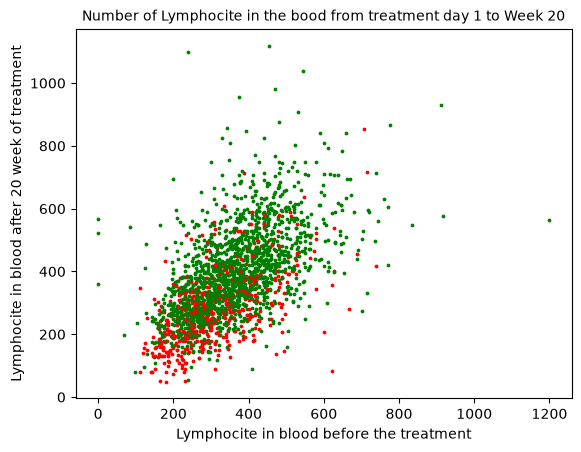

In [22]:
#Scatter plot

colors = {1: 'r', 0: 'g'}

fig, ax = plt.subplots()

for i in range (len(data1)):
    ax.scatter(data1.cd40[i], data1.cd420[i], s = 3, marker = 'o' ,color = colors[data1["infected"][i]])
ax.set_title("Number of Lymphocite in the bood from treatment day 1 to Week 20", size = 10)
ax.set_xlabel("Lymphocite in blood before the treatment")
ax.set_ylabel("Lymphocite in blood after 20 week of treatment")

plt.show()

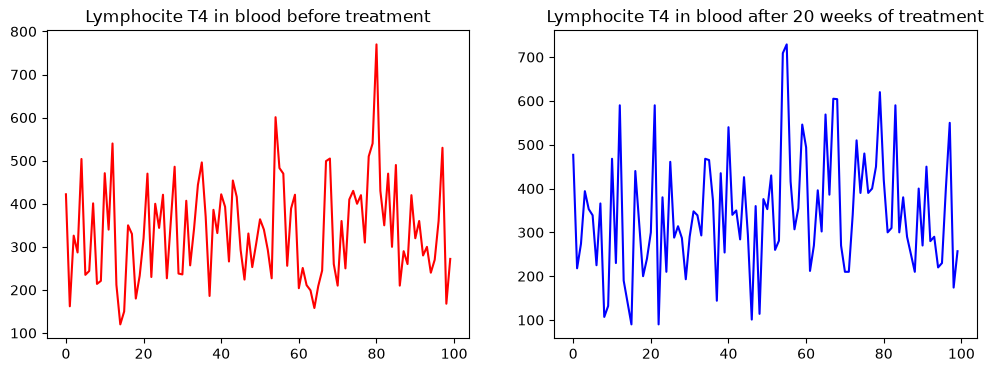

In [23]:
# plot

fig, ax = plt.subplots(1, 2, figsize = (12, 4))
ax[0].plot(data1.cd40.head(100), c='r')
ax[0].set_title("Lymphocite T4 in blood before treatment")
ax[1].plot(data1.cd420.head(100), c='b')
ax[1].set_title("Lymphocite T4 in blood after 20 weeks of treatment")

plt.show()

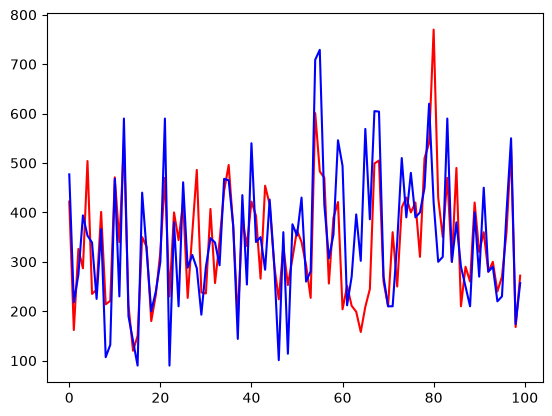

In [24]:
# plot both of them on the same graph

fig, ax = plt.subplots()
ax.plot(data1.cd40.head(100), c='r')
ax.plot(data1.cd420.head(100), c='b')

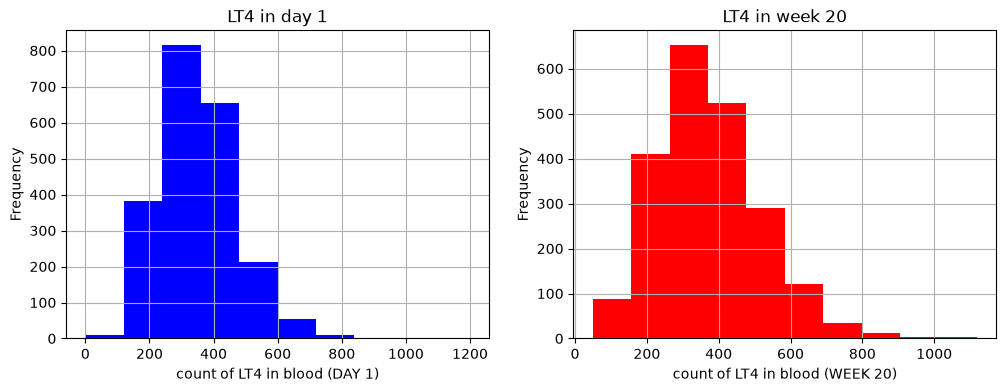

In [25]:
#histogram

fig, ax = plt.subplots(1, 2, figsize = (12, 4))
ax[0].hist(data1.cd40, color = "b")
ax[0].grid(True)
ax[0].set_title("LT4 in day 1")
ax[0].set_xlabel("count of LT4 in blood (DAY 1)")
ax[0].set_ylabel("Frequency")

ax[1].hist(data1.cd420, color = "r")
ax[1].grid(True)
ax[1].set_title("LT4 in week 20")
ax[1].set_xlabel("count of LT4 in blood (WEEK 20)")
ax[1].set_ylabel("Frequency")

plt.show()

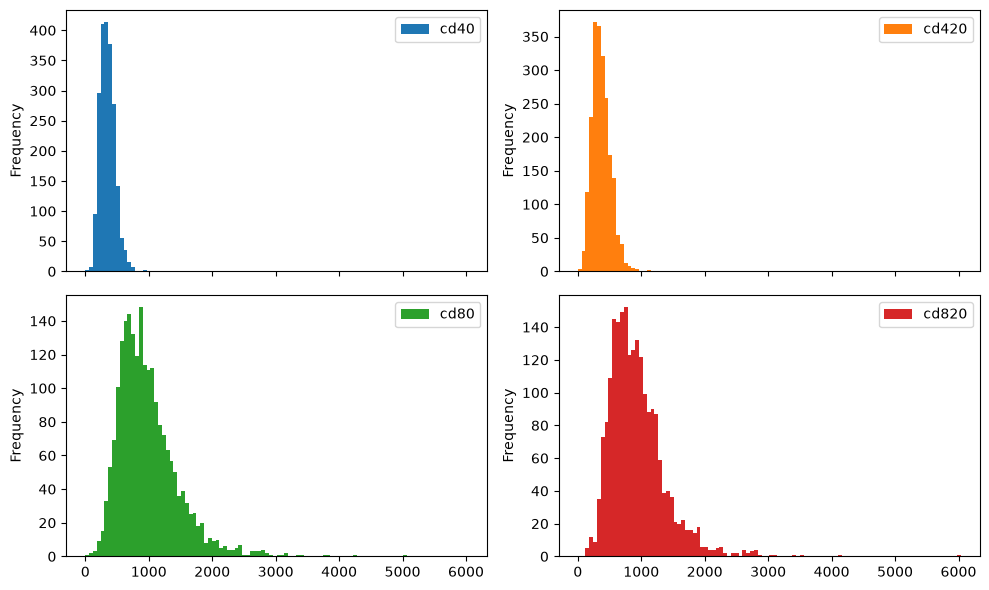

In [26]:
columns = ["cd40", "cd420", "cd80", "cd820"]
data1[columns].plot.hist(subplots = True, layout=(2,2), figsize =(10,6), bins = 100)
plt.tight_layout()
plt.show()

In [27]:
# bar chart


In [28]:
data1.cd40.value_counts()

cd40
300    27
280    24
420    23
320    19
410    19
       ..
122     1
128     1
739     1
152     1
911     1
Name: count, Length: 484, dtype: int64

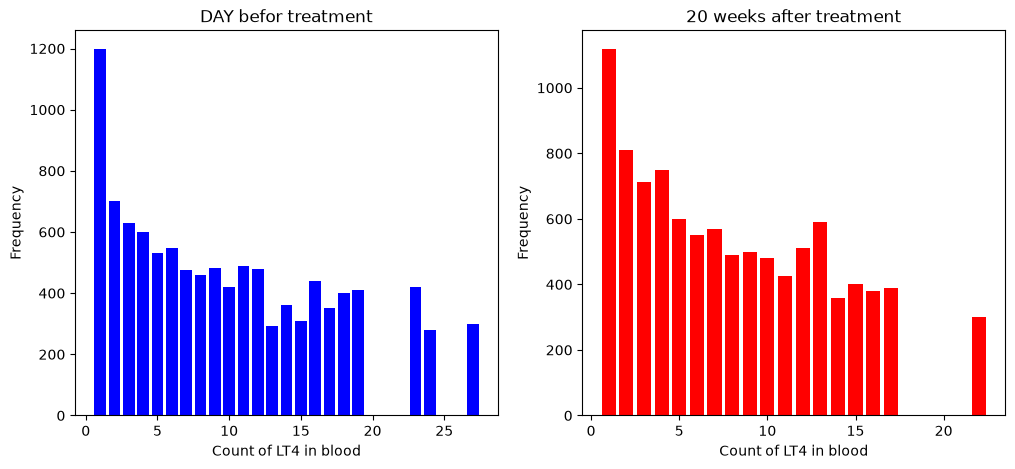

In [29]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))

dt1 = data1.cd40.value_counts()
dt2 = data1.cd420.value_counts()

x1_index = dt1.index
x1_value = dt1.values

x2_index = dt2.index
x2_value = dt2.values


# calling each axis

ax[0].bar(x1_value, x1_index, color = "b")
ax[0].set_title("DAY befor treatment")
ax[0].set_xlabel("Count of LT4 in blood")
ax[0].set_ylabel("Frequency")

ax[1].bar(x2_value, x2_index, color = "r")
ax[1].set_title("20 weeks after treatment")
ax[1].set_xlabel("Count of LT4 in blood")
ax[1].set_ylabel("Frequency")

plt.show()

In [30]:
# horizontal bar

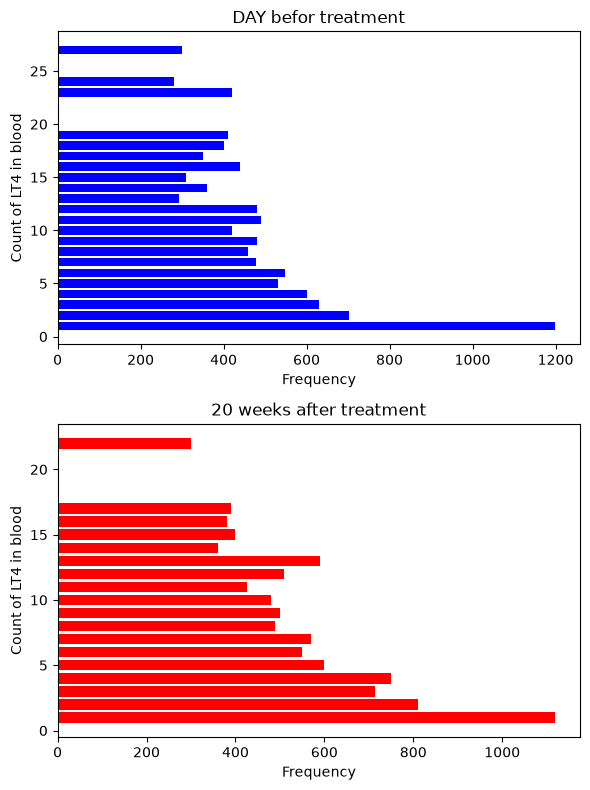

In [31]:
fig, ax = plt.subplots(2, 1, figsize=(6, 8))

dt1 = data1.cd40.value_counts()
dt2 = data1.cd420.value_counts()

x1_index = dt1.index
x1_value = dt1.values

x2_index = dt2.index
x2_value = dt2.values

# calling each axis

ax[0].barh(x1_value, x1_index, color = "b")
ax[0].set_title("DAY befor treatment")
ax[0].set_xlabel("Frequency")
ax[0].set_ylabel("Count of LT4 in blood")

ax[1].barh(x2_value, x2_index, color = "r")
ax[1].set_title("20 weeks after treatment")
ax[1].set_xlabel("Frequency")
ax[1].set_ylabel("Count of LT4 in blood")

plt.tight_layout()
plt.show()

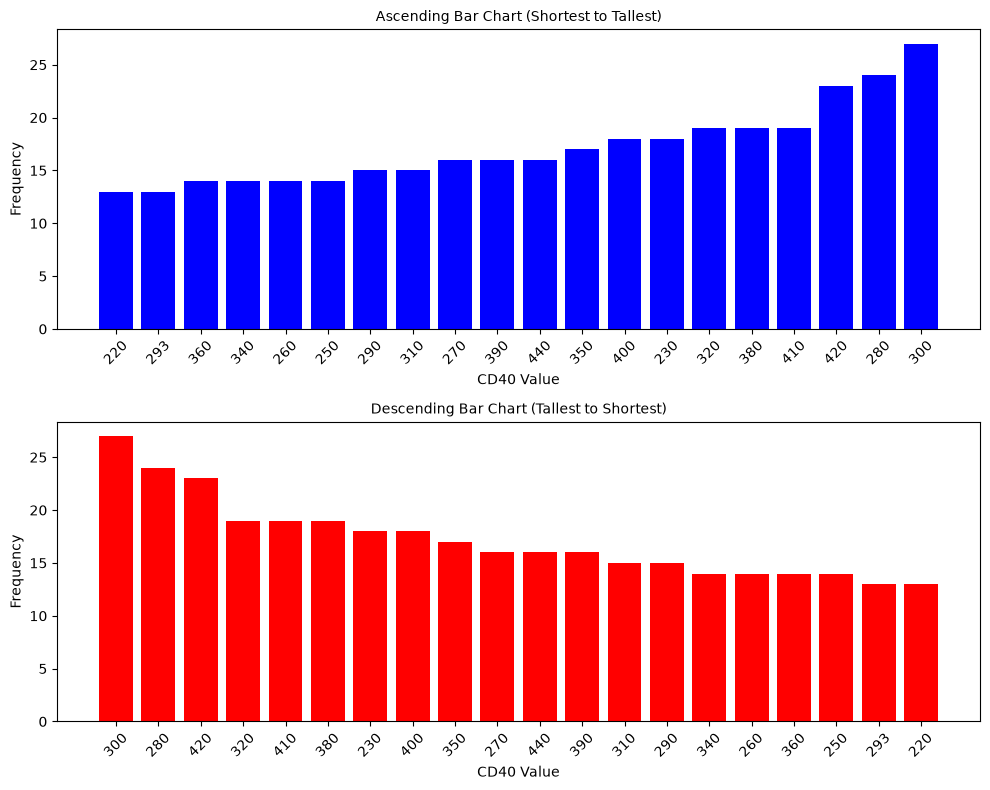

In [32]:
# Ascending and Descending bar
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

asc_inp = data1['cd40'].value_counts().sort_values(ascending=True)
desc_inp = data1['cd40'].value_counts().sort_values(ascending=False)

# Ascending 
asc_top = asc_inp.tail(20)
ax[0].bar(asc_top.index.astype(str), asc_top.values, color='b')
ax[0].set_title("Ascending Bar Chart (Shortest to Tallest)", size=10)
ax[0].set_xlabel("CD40 Value")
ax[0].set_ylabel("Frequency")
ax[0].tick_params(axis='x', rotation=45)

# Descending 
desc_top = desc_inp.head(20)
ax[1].bar(desc_top.index.astype(str), desc_top.values, color='r')
ax[1].set_title("Descending Bar Chart (Tallest to Shortest)", size=10)
ax[1].set_xlabel("CD40 Value")
ax[1].set_ylabel("Frequency")
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [33]:
data1.cd40.value_counts().sort_values(ascending=False).head(20)

cd40
300    27
280    24
420    23
320    19
410    19
380    19
230    18
400    18
350    17
270    16
440    16
390    16
310    15
290    15
340    14
260    14
360    14
250    14
293    13
220    13
Name: count, dtype: int64

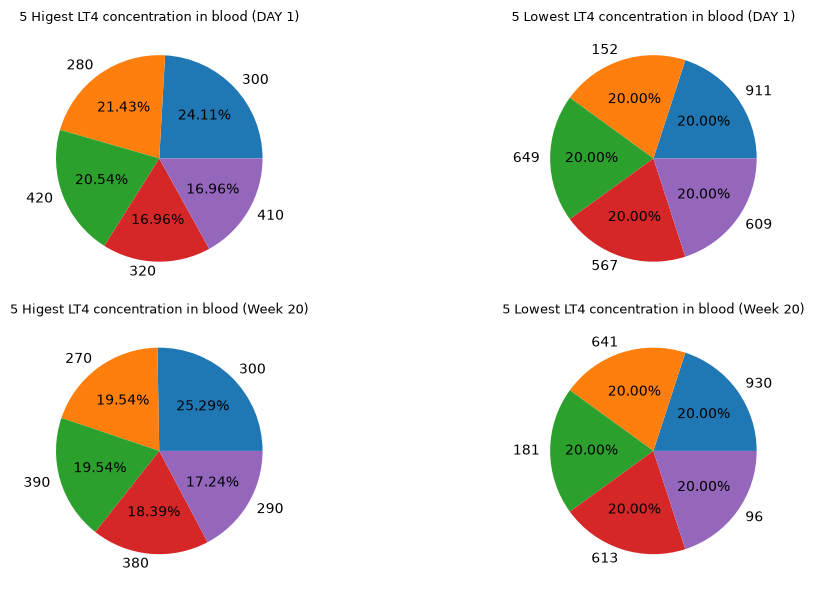

In [34]:
#Chart Pie

count_asc = data1.cd40.value_counts().sort_values(ascending=False).head(5)
count_desc = data1.cd40.value_counts().sort_values(ascending=True).head(5)
count_asc2 = data1.cd420.value_counts().sort_values(ascending=False).head(5)
count_desc2 = data1.cd420.value_counts().sort_values(ascending=True).head(5)

fig, ax = plt.subplots(2, 2, figsize = (12, 6))

label1 = count_asc.index
label2 = count_desc.index
label3 = count_asc2.index
label4 = count_desc2.index

ax[0,0].pie(count_asc, labels = label1, autopct='%1.2f%%')
ax[0,0].set_title("5 Higest LT4 concentration in blood (DAY 1)", size = 9)

ax[0,1].pie(count_desc, labels = label2, autopct='%1.2f%%')
ax[0,1].set_title("5 Lowest LT4 concentration in blood (DAY 1)", size = 9)

ax[1,0].pie(count_asc2, labels = label3, autopct='%1.2f%%')
ax[1,0].set_title("5 Higest LT4 concentration in blood (Week 20)", size = 9)

ax[1,1].pie(count_desc2, labels = label4, autopct='%1.2f%%')
ax[1,1].set_title("5 Lowest LT4 concentration in blood (Week 20)", size = 9)


plt.tight_layout()
plt.show()

In [35]:
# HeatMap

import seaborn as sns

In [36]:
data1

,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820,infected
0,948,2,48,89.8128,0,0,0,100,0,0,0,0,0,0,1,0,1,0,422,477,566,324,0
1,1002,3,61,49.4424,0,0,0,90,0,1,895,0,0,1,3,0,1,0,162,218,392,564,1
2,961,3,45,88.4520,0,1,1,90,0,1,707,0,1,1,3,0,1,1,326,274,2063,1893,0
3,1166,3,47,85.2768,0,1,0,100,0,1,1399,0,1,1,3,0,1,0,287,394,1590,966,0
4,1090,0,43,66.6792,0,1,0,100,0,1,1352,0,1,1,3,0,0,0,504,353,870,782,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2134,1091,3,21,53.2980,1,0,0,100,0,1,842,0,1,1,3,0,1,1,152,109,561,720,0
2135,395,0,17,102.9672,1,0,0,100,0,1,417,1,1,1,3,0,0,1,373,218,1759,1030,0
2136,1104,2,53,69.8544,1,1,0,90,0,1,753,1,1,1,3,0,1,0,419,364,1391,1041,0
2137,465,0,14,60.0000,1,0,0,100,0,0,0,0,1,0,1,0,0,0,166,169,999,1838,1


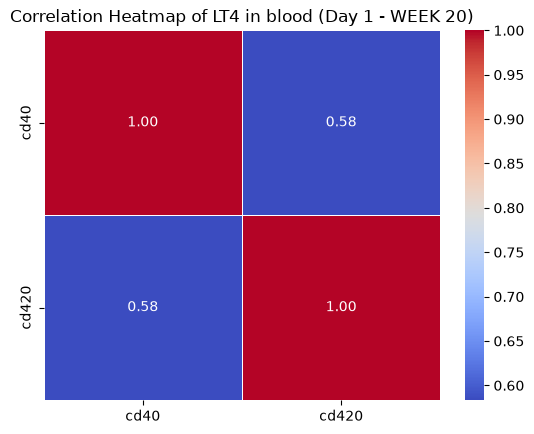

In [37]:
correlation = data1.iloc[:,[18,19]].corr()
fig, ax = plt.subplots()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap of LT4 in blood (Day 1 - WEEK 20)')
plt.show()

In [38]:
data1['cd420'].value_counts().head(10).index

Index([300, 270, 390, 380, 290, 400, 310, 250, 320, 360], dtype='int64', name='cd420')

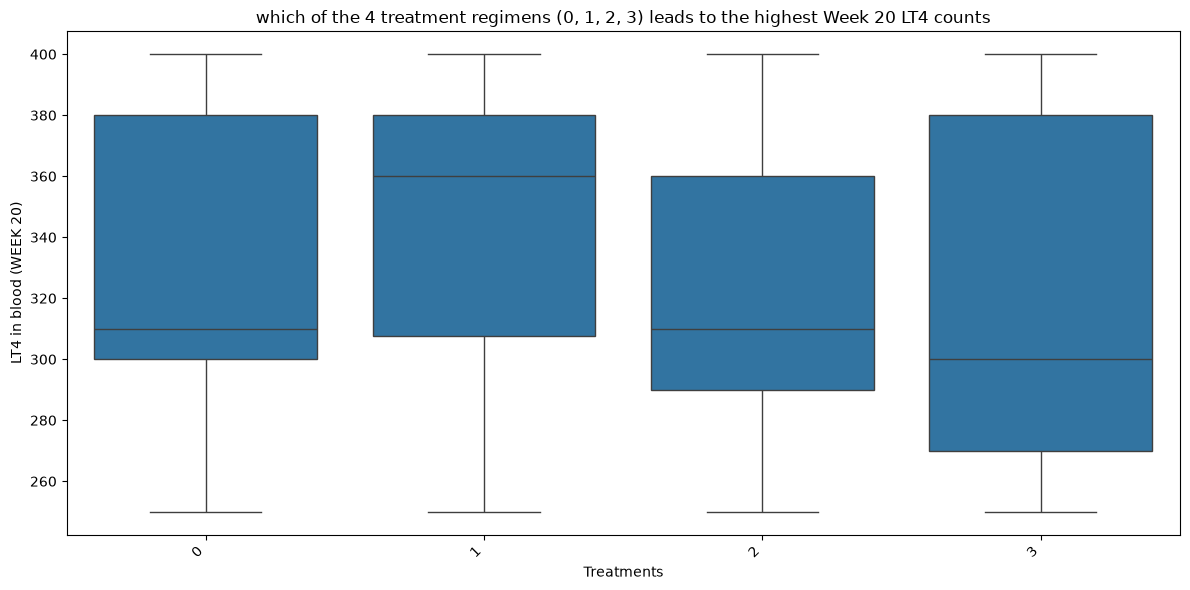

In [39]:
# Japanese candle BOX PLOT

top_varieties = data1['cd420'].value_counts().head(10).index
df_top = data1[data1['cd420'].isin(top_varieties)]

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data= df_top, x='trt', y='cd420', ax=ax)
ax.set_title('which of the 4 treatment regimens (0, 1, 2, 3) leads to the highest Week 20 LT4 counts')
ax.set_xlabel('Treatments')
ax.set_ylabel('LT4 in blood (WEEK 20)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

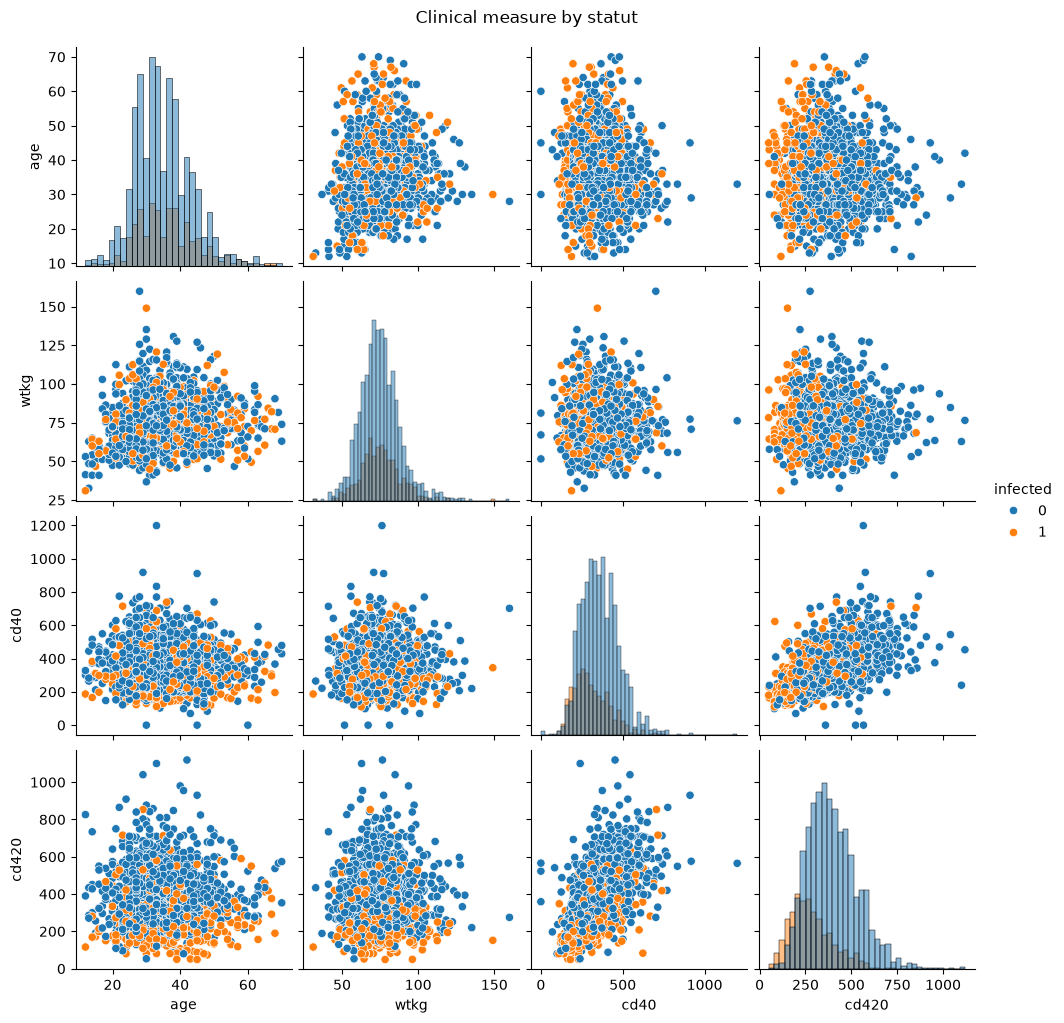

In [40]:
# PairPLOT
cols = ['age', 'wtkg', 'cd40', 'cd420']

sns.pairplot(data1, vars=cols, hue='infected', diag_kind='hist')
plt.suptitle('Clinical measure by statut', y=1.02)
plt.show()

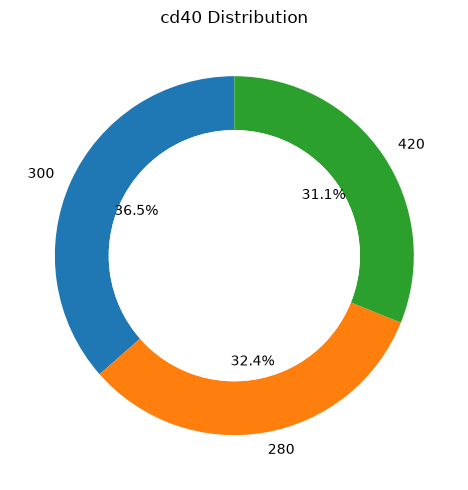

In [41]:
#Donut PLOT

counts = data1['cd40'].value_counts().head(3)
fig, ax = plt.subplots(figsize=(5,5))

ax.pie(counts, labels=counts.index, autopct='%1.1f%%',startangle=90, wedgeprops=dict(width=0.3))
ax.set_title('cd40 Distribution')

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)
plt.tight_layout()
plt.show()

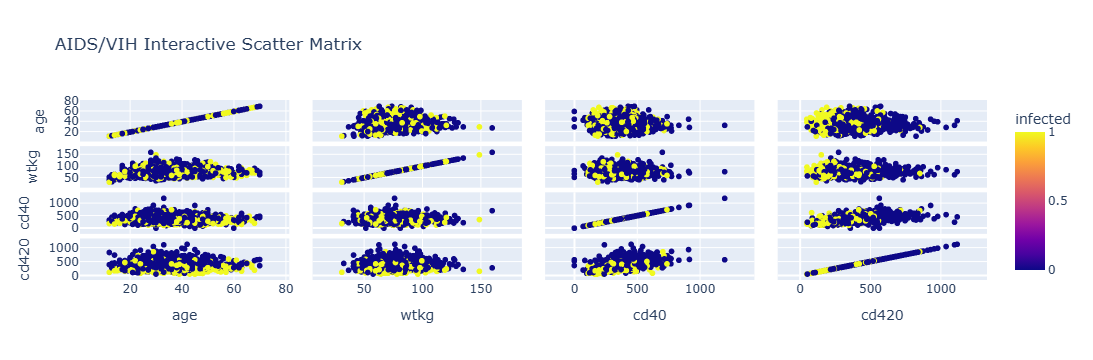

In [42]:
# Interactive scatter matrix

import plotly.express as px

fig = px.scatter_matrix(data1, dimensions=['age', 'wtkg', 'cd40', 'cd420'],
                        color='infected', title='AIDS/VIH Interactive Scatter Matrix')
fig.show()

In [43]:
fig = px.scatter_3d(data1, x='age', y='wtkg', z='cd40',
                     color='infected', title='AIDS/VIH 3D Scatter Plot')
fig.show()

# DATA VISUALIZATION PART 2

In [44]:
data2.head(5)

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,Current Ratio,Net Profit Margin,Number of Employees,Inflation Rate(in US)
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.11,0.8794,25.3096,164000,8.0028
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.61,1.0746,25.8818,154000,4.6979
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.28,1.3636,20.9136,147000,1.2336
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.97,1.5401,21.2381,137000,1.8122
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.98,1.1329,22.4142,132000,2.4426


In [45]:
data2["Category"].value_counts()

Category
IT               43
ELEC             29
Bank             14
Manufacturing    14
FOOD             14
BANK             14
LOGI             14
Finance          10
FinTech           9
Name: count, dtype: int64

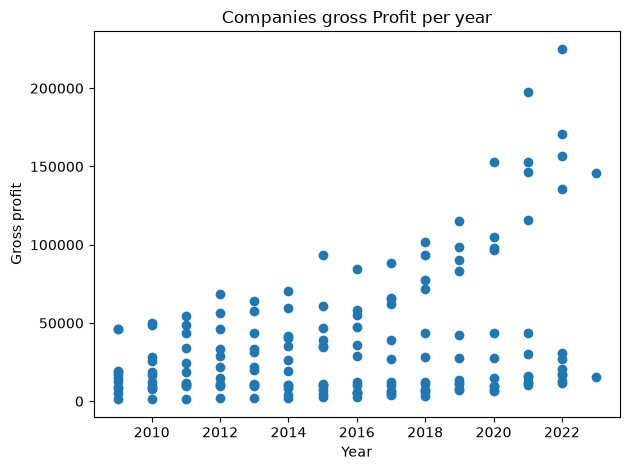

In [46]:
# scatter plot

fig, ax = plt.subplots()

ax.scatter(data2["Year"], data2["Gross Profit"])
ax.set_xlabel('Year')
ax.set_ylabel('Gross profit')
ax.set_title('Companies gross Profit per year')

plt.tight_layout()
plt.show()

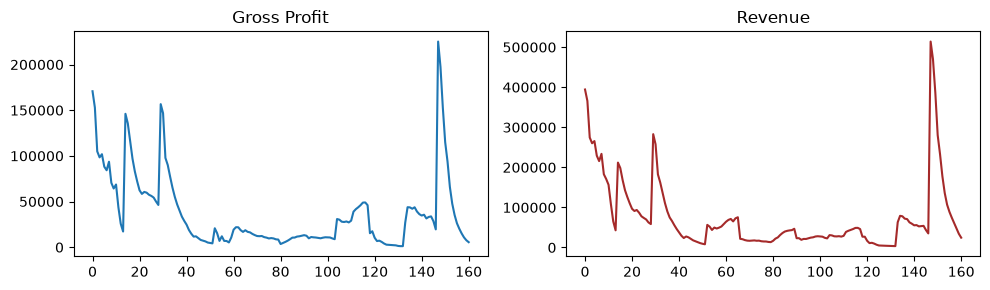

In [47]:
#plot

fig, ax = plt.subplots(1, 2, figsize=(10,3))

ax[0].plot(data2["Gross Profit"])
ax[0].set_title('Gross Profit')
ax[1].plot(data2["Revenue"], c='brown')
ax[1].set_title("Revenue")

plt.tight_layout()
plt.show()

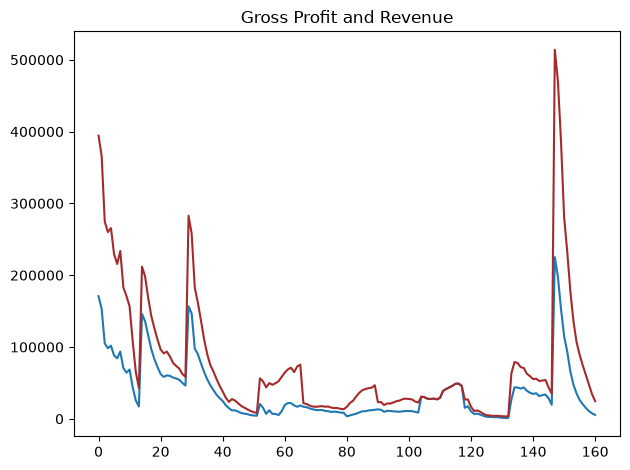

In [48]:
fig, ax = plt.subplots()

ax.plot(data2["Gross Profit"])
ax.set_title('Gross Profit and Revenue')
ax.plot(data2["Revenue"], c='brown')

plt.tight_layout()
plt.show()

In [49]:
#Histogram

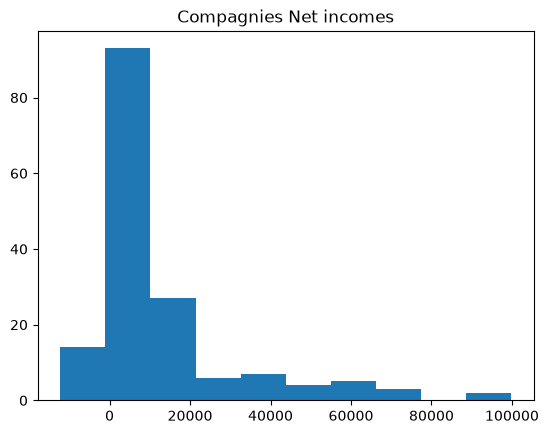

In [50]:
plt.hist(data2["Net Income"])
plt.title("Compagnies Net incomes")
plt.show()

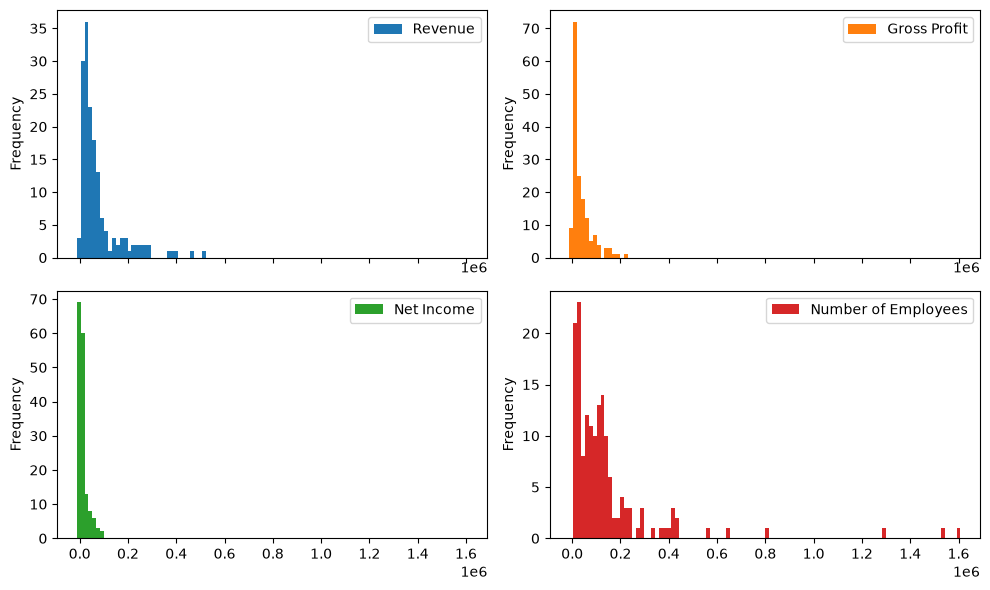

In [51]:
columns = ["Revenue", "Gross Profit", "Net Income", "Number of Employees"]
data2[columns].plot.hist(subplots = True, layout=(2,2), figsize =(10,6), bins = 100)
plt.tight_layout()
plt.show()

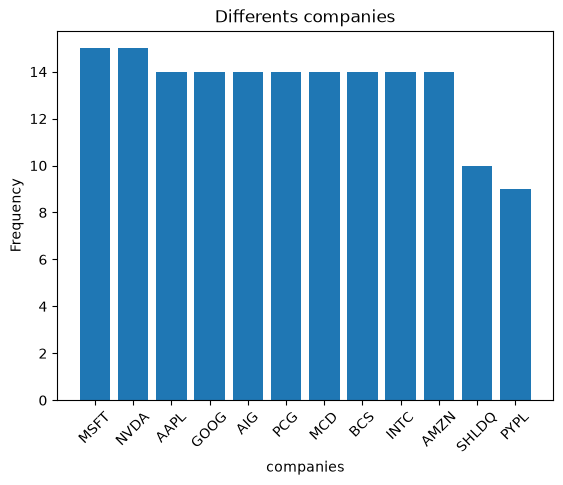

In [52]:
fig, ax = plt.subplots()

dt = data2["Company "].value_counts()


x_index = dt.index
x_value = dt.values

# Plotting

ax.bar(x_index, x_value)
ax.set_title("Differents companies")
ax.set_xlabel("companies")
ax.set_ylabel("Frequency")

plt.xticks(rotation=45)
plt.show()

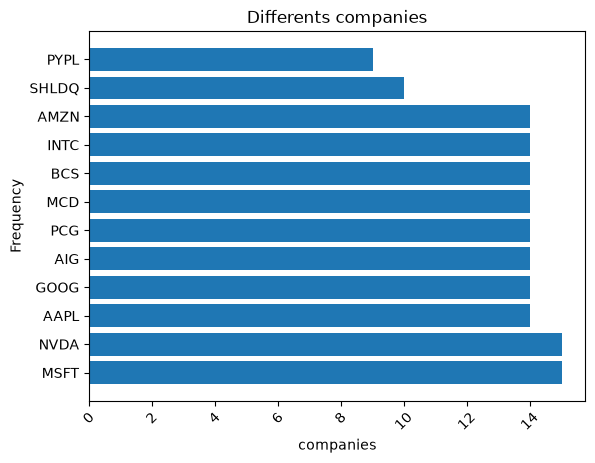

In [53]:
fig, ax = plt.subplots()

dt = data2["Company "].value_counts()


x_index = dt.index
x_value = dt.values

# Plotting

ax.barh(x_index, x_value)
ax.set_title("Differents companies")
ax.set_xlabel("companies")
ax.set_ylabel("Frequency")

plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='Company '>

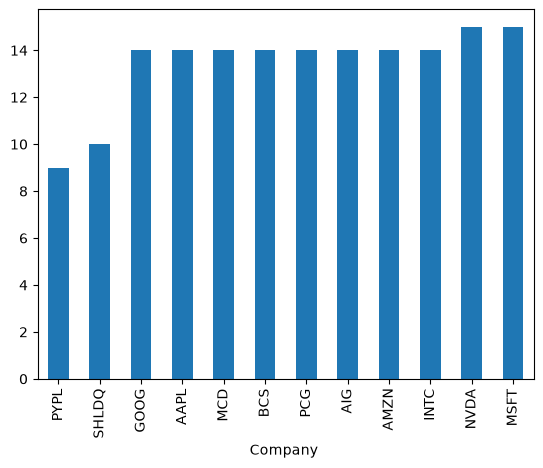

In [54]:
# Bar Chart increasing for the companies

data2["Company "].value_counts().sort_values(ascending=True).plot.bar()

<Axes: xlabel='Category'>

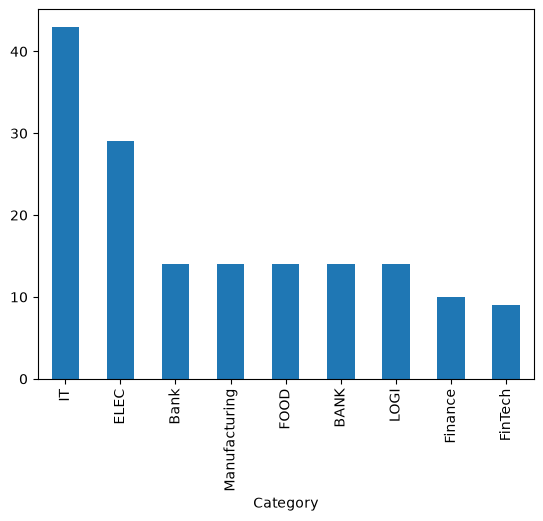

In [55]:
# Bar Chart descreasing for the categories

data2["Category"].value_counts().sort_values(ascending=False).plot.bar()

<Axes: >

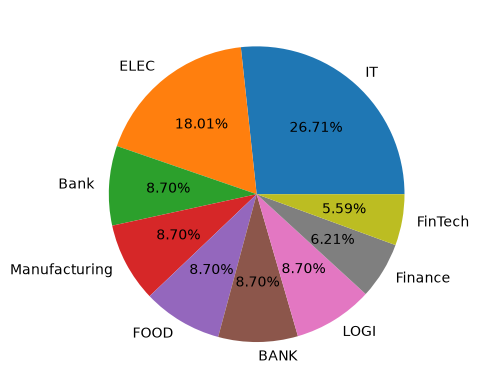

In [56]:
data2["Category"].value_counts().plot.pie(autopct="%1.2f%%")

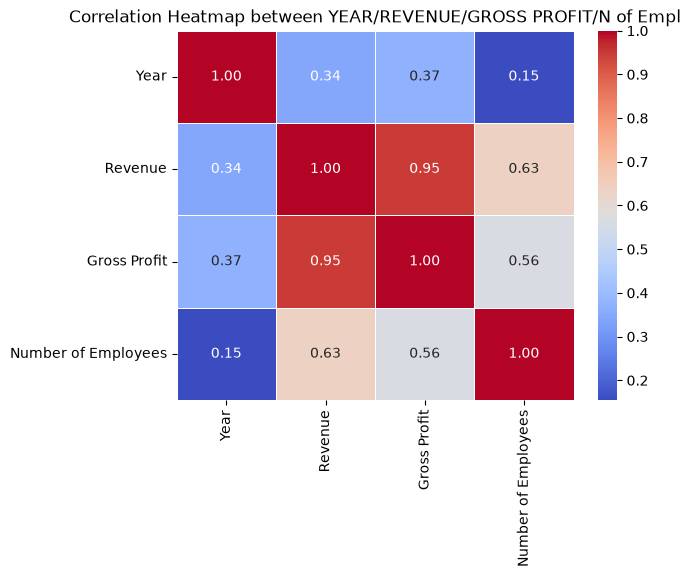

In [57]:
# HeatMap with SEABORN
columns = ["Year", "Revenue", "Gross Profit", "Number of Employees"]
correlation = data2[columns].corr()
fig, ax = plt.subplots()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap between YEAR/REVENUE/GROSS PROFIT/N of Empl')

plt.show()

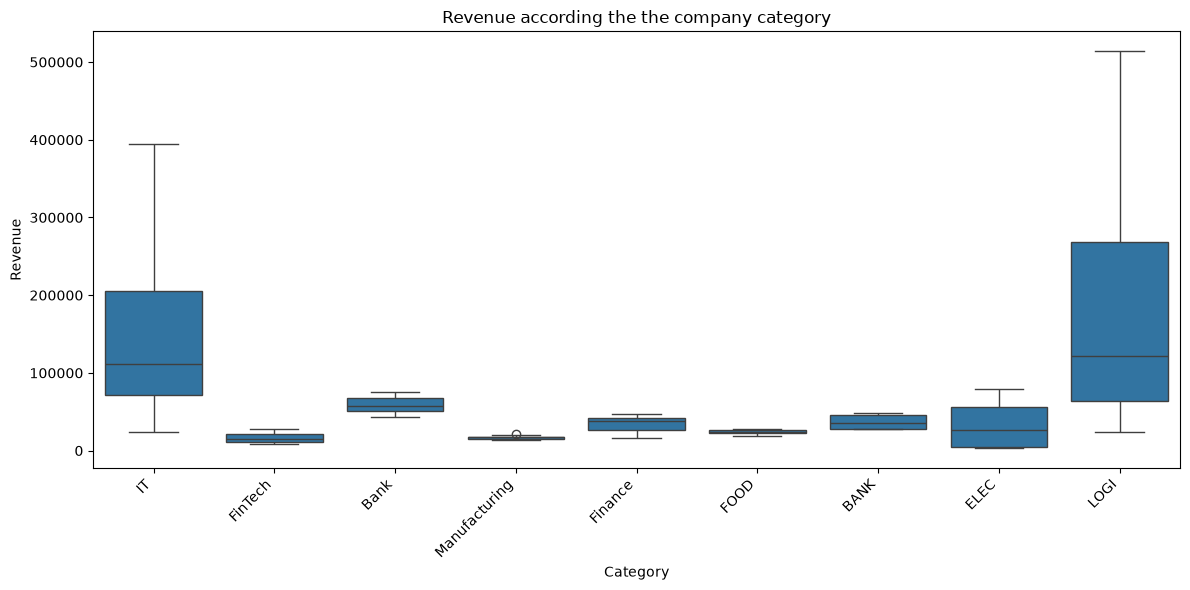

In [58]:
# Box plot

varieties = data2['Category'].value_counts().head(10).index
df_top = data2[data2['Category'].isin(varieties)]

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data= df_top, x='Category', y='Revenue', ax=ax)
ax.set_title('Revenue according the the company category')
ax.set_xlabel('Category')
ax.set_ylabel('Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

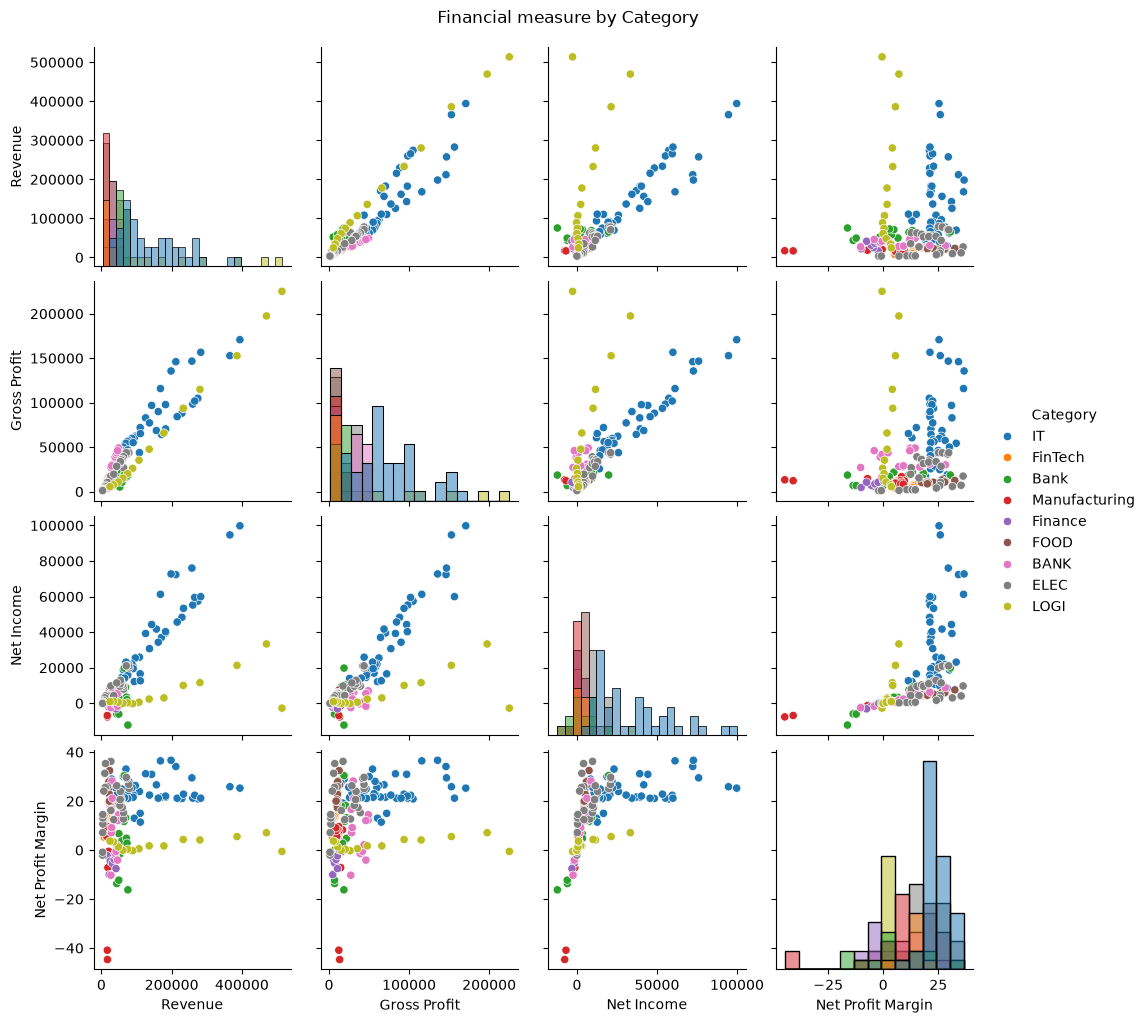

In [59]:
# PairPLOT
cols = ['Revenue', 'Gross Profit', 'Net Income', 'Net Profit Margin']

sns.pairplot(data2, vars=cols, hue='Category', diag_kind='hist')
plt.suptitle('Financial measure by Category', y=1.02)
plt.show()

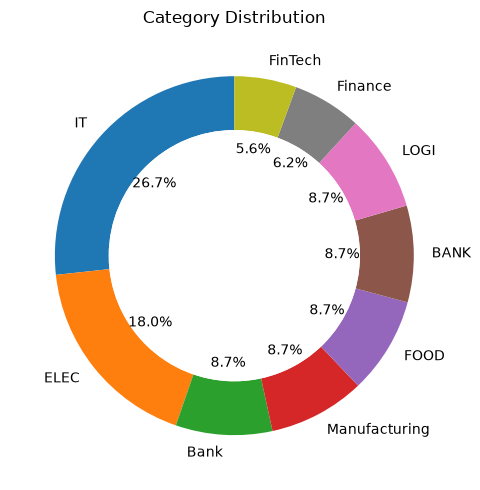

In [60]:
# DONUT PIE

counts = data2['Category'].value_counts()
fig, ax = plt.subplots(figsize=(5,5))

ax.pie(counts, labels=counts.index, autopct='%1.1f%%',startangle=90, wedgeprops=dict(width=0.3))
ax.set_title('Category Distribution')

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)
plt.tight_layout()
plt.show()

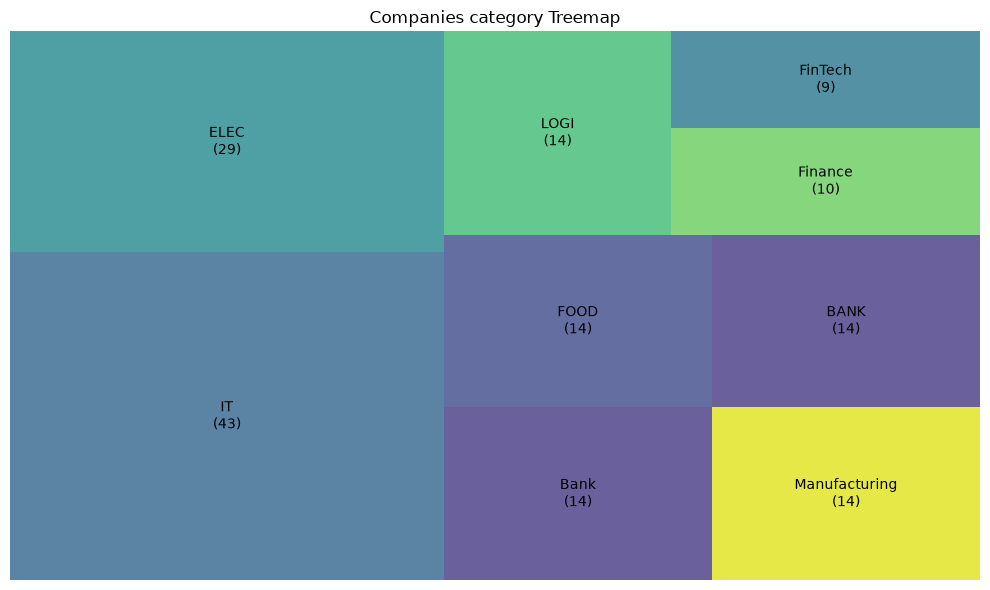

In [61]:
# Treemap 
import squarify

top_categories = data2['Category'].value_counts()
freq = top_categories.values
labels = [f"{Category}\n({freq})" for Category, freq in zip(top_categories.index, freq)]

fig, ax = plt.subplots(figsize=(10,6))
squarify.plot(sizes=freq, label=labels, alpha=0.8, ax=ax)
ax.set_title('Companies category Treemap')
ax.axis('off')
plt.tight_layout()
plt.show()

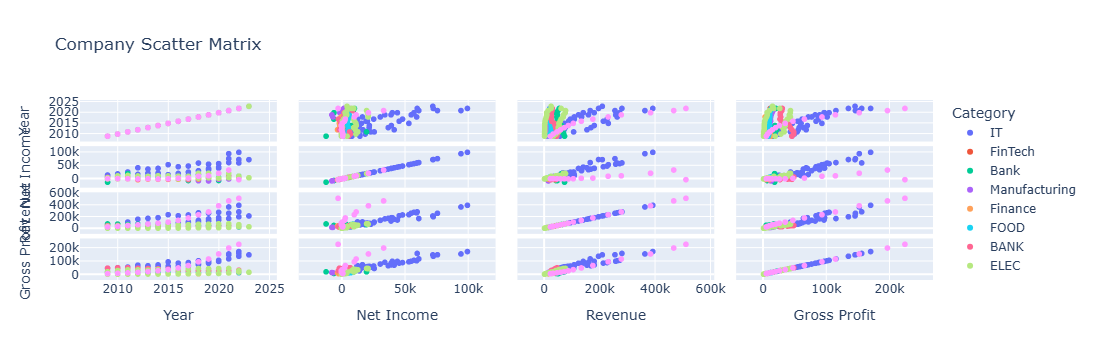

In [62]:
# Interactive Scatter

fig = px.scatter_matrix(data2, dimensions=['Year', 'Net Income', 'Revenue', 'Gross Profit'],
                        color='Category', title='Company Scatter Matrix')
fig.show()

In [63]:
fig = px.scatter_3d(data2, x='Year', y='Gross Profit', z='Net Income',
                     color='Category', title='Companies 3D Scatter Plot')
fig.show()

# MACHINE LEARNING MODELS

### LINEAR REGRESSION ONE VARIABLE

In [64]:
data2.head(5)

,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,Current Ratio,Net Profit Margin,Number of Employees,Inflation Rate(in US)
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.11,0.8794,25.3096,164000,8.0028
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.61,1.0746,25.8818,154000,4.6979
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.28,1.3636,20.9136,147000,1.2336
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.97,1.5401,21.2381,137000,1.8122
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.98,1.1329,22.4142,132000,2.4426


In [65]:
drop = ["Company ", "Category"]
data2 = data2.drop(drop, axis=1)

data2

,Year,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,Current Ratio,Net Profit Margin,Number of Employees,Inflation Rate(in US)
0,2022,2066.94,394328.0,170782.0,99803.0,6.1100,0.8794,25.3096,164000,8.0028
1,2021,2913.28,365817.0,152836.0,94680.0,5.6100,1.0746,25.8818,154000,4.6979
2,2020,2255.97,274515.0,104956.0,57411.0,3.2800,1.3636,20.9136,147000,1.2336
3,2019,1304.76,260174.0,98392.0,55256.0,2.9700,1.5401,21.2381,137000,1.8122
4,2018,748.54,265595.0,101839.0,59531.0,2.9800,1.1329,22.4142,132000,2.4426
...,...,...,...,...,...,...,...,...,...,...
156,2013,182.54,74452.0,20271.0,274.0,0.0295,1.0716,0.3680,117300,1.4648
157,2012,113.63,61093.0,15122.0,-39.0,-0.0045,1.1207,-0.0638,88400,2.0693
158,2011,78.72,48077.0,10789.0,631.0,0.0685,1.1741,1.3125,56200,3.1568
159,2010,80.79,34204.0,7643.0,1152.0,0.1265,1.3254,3.3680,33700,1.6400


In [66]:
dataset1 = data2.to_numpy()

In [67]:
print(type(dataset1))

<class 'numpy.ndarray'>


In [68]:
dataset1

array([[ 2.02200e+03,  2.06694e+03,  3.94328e+05, ...,  2.53096e+01,
         1.64000e+05,  8.00280e+00],
       [ 2.02100e+03,  2.91328e+03,  3.65817e+05, ...,  2.58818e+01,
         1.54000e+05,  4.69790e+00],
       [ 2.02000e+03,  2.25597e+03,  2.74515e+05, ...,  2.09136e+01,
         1.47000e+05,  1.23360e+00],
       ...,
       [ 2.01100e+03,  7.87200e+01,  4.80770e+04, ...,  1.31250e+00,
         5.62000e+04,  3.15680e+00],
       [ 2.01000e+03,  8.07900e+01,  3.42040e+04, ...,  3.36800e+00,
         3.37000e+04,  1.64000e+00],
       [ 2.00900e+03,  5.82400e+01,  2.45090e+04, ...,  3.68030e+00,
         2.43000e+04, -3.55500e-01]], shape=(161, 10))

In [69]:
#Define variables

X = dataset1[:, 2:3]
y = dataset1[:, 3:4]
m = y.shape[0]

In [70]:
#Normalization

X_mean = np.mean(X, axis = 0)
X_std = np.std(X, 0)

X_normalized = (X - X_mean) / X_std
X_normalized 

array([[ 3.51877933e+00],
       [ 3.20375636e+00],
       [ 2.19494475e+00],
       [ 2.03648856e+00],
       [ 2.09638613e+00],
       [ 1.69462714e+00],
       [ 1.54441364e+00],
       [ 1.74413849e+00],
       [ 1.18151459e+00],
       [ 1.05019517e+00],
       [ 8.91064979e-01],
       [ 3.57842933e-01],
       [-1.17536693e-01],
       [-3.64154237e-01],
       [ 1.50326652e+00],
       [ 1.35250055e+00],
       [ 1.01901440e+00],
       [ 7.41978486e-01],
       [ 5.52242085e-01],
       [ 3.81167737e-01],
       [ 2.28810689e-01],
       [ 1.68957318e-01],
       [ 1.95762612e-01],
       [ 1.21213841e-01],
       [ 2.19480691e-02],
       [-2.36408192e-02],
       [-6.54066937e-02],
       [-1.47822476e-01],
       [-1.92538480e-01],
       [ 2.28688492e+00],
       [ 2.00845681e+00],
       [ 1.17855341e+00],
       [ 9.50167006e-01],
       [ 6.73517809e-01],
       [ 3.86637078e-01],
       [ 1.59211947e-01],
       [-9.65256603e-03],
       [-1.08962534e-01],
       [-2.2

In [71]:
# Hypothesis

def hypothesis(x, theta=[[0],[0]]):
    return theta[0] + theta[1]*x

In [72]:
hypothesis(X_normalized)

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],

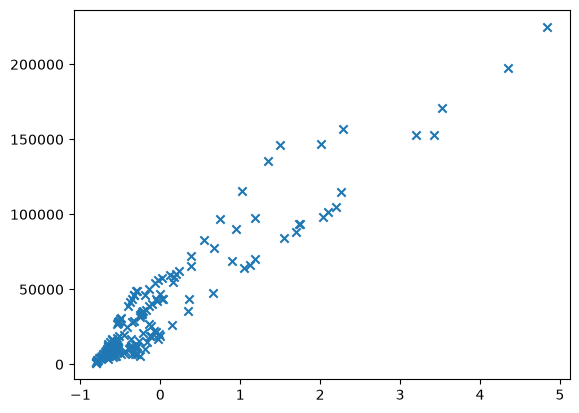

In [73]:
# plot to see the graph

plt.scatter(X_normalized, y, marker = 'x')

In [74]:
# Coast function

def costFunction(X, y, theta=[[0],[0]]):
    m = len(y)
    X_ext = np.c_[np.ones(m), X]
    hypothesis = X_ext.dot(theta)
    cost = (hypothesis - y) ** 2

    return 1/(2*m) * cost

In [75]:
cost1 = costFunction(X_normalized, y)
cost1

array([[9.05791662e+07],
       [7.25429904e+07],
       [3.42104408e+07],
       [3.00651729e+07],
       [3.22086395e+07],
       [2.41514615e+07],
       [2.20504757e+07],
       [2.72230679e+07],
       [1.54517651e+07],
       [1.28416286e+07],
       [1.46412119e+07],
       [5.96278610e+06],
       [2.04865794e+06],
       [9.21109578e+05],
       [6.62459214e+07],
       [5.71204484e+07],
       [4.16851327e+07],
       [2.91825527e+07],
       [2.13598835e+07],
       [1.61025095e+07],
       [1.20575655e+07],
       [1.05823723e+07],
       [1.13830241e+07],
       [1.10890063e+07],
       [1.02550040e+07],
       [9.80637655e+06],
       [9.17907440e+06],
       [7.79163951e+06],
       [6.65224697e+06],
       [7.61922257e+07],
       [6.68332398e+07],
       [2.97014349e+07],
       [2.51334830e+07],
       [1.85424003e+07],
       [1.32311614e+07],
       [9.44024210e+06],
       [6.80925660e+06],
       [5.04626118e+06],
       [3.49066048e+06],
       [2.58718251e+06],


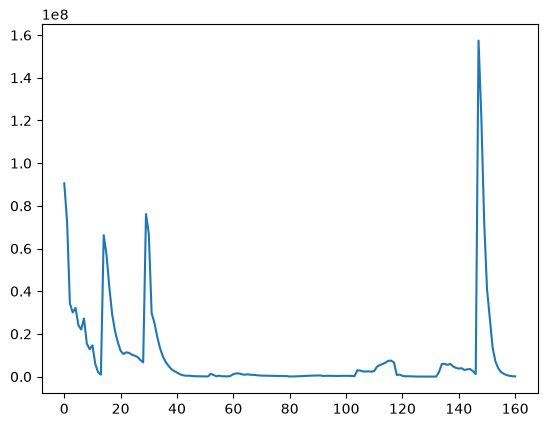

In [76]:
plt.plot(cost1)
plt.show()

In [77]:
# Gradient Descent
def gradientDescent(X,y,theta=[[0],[0]], alpha=0.01, num_iters=1500):
    m= y.size
    X_extend= np.c_[np.ones(m), X]
    J_history= np.zeros(num_iters)
    
    for i in range(num_iters):
        h= X_extend.dot(theta)
        errors = h - y
        theta = theta - (alpha / m) * X_extend.T.dot(errors)
        J_history[i] = (1/(2*m)) * np.sum((h - y)**2)
    return(theta,J_history)

In [78]:
theta, j_hist = gradientDescent(X_normalized, y)

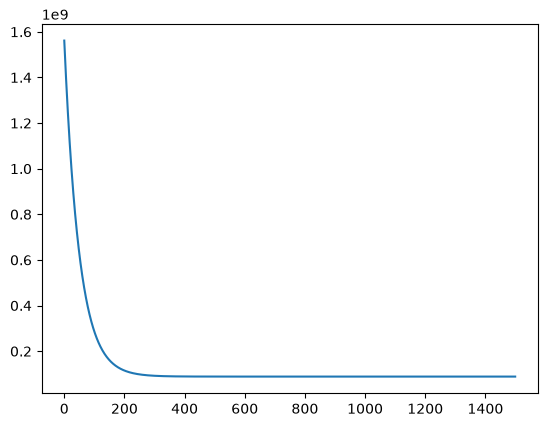

In [79]:
plt.plot(j_hist)

In [80]:
print(f"thetha 0: {theta[0]} and theta 1: {theta[1]}")

thetha 0: [37383.45252018] and theta 1: [39345.74075875]


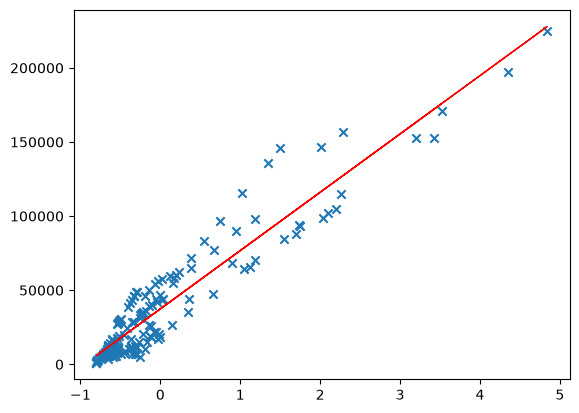

In [81]:
plt.scatter(X_normalized, y, marker = 'x')
plt.plot(X_normalized, hypothesis(X_normalized, theta), c='r', linewidth=1)
plt.show()

In [82]:
# prediction test

predict1 = 510300.0
predict_norm = (predict1 - X_mean) / X_std

pred_ext = np.c_[1, predict_norm]

pred_ext

array([[1.        , 4.80017404]])

In [83]:
print(f"The gross profit is estimated at: {pred_ext.dot(theta)}")

The gross profit is estimated at: [[226249.85596926]]


### Linear Regression multiple variables

In [84]:
dataset1

array([[ 2.02200e+03,  2.06694e+03,  3.94328e+05, ...,  2.53096e+01,
         1.64000e+05,  8.00280e+00],
       [ 2.02100e+03,  2.91328e+03,  3.65817e+05, ...,  2.58818e+01,
         1.54000e+05,  4.69790e+00],
       [ 2.02000e+03,  2.25597e+03,  2.74515e+05, ...,  2.09136e+01,
         1.47000e+05,  1.23360e+00],
       ...,
       [ 2.01100e+03,  7.87200e+01,  4.80770e+04, ...,  1.31250e+00,
         5.62000e+04,  3.15680e+00],
       [ 2.01000e+03,  8.07900e+01,  3.42040e+04, ...,  3.36800e+00,
         3.37000e+04,  1.64000e+00],
       [ 2.00900e+03,  5.82400e+01,  2.45090e+04, ...,  3.68030e+00,
         2.43000e+04, -3.55500e-01]], shape=(161, 10))

In [85]:
# input & output
# inputs are Revenue, Net income, Number of employees 
X2 = dataset1[:, [2,4,8]]
X2

array([[ 3.943280e+05,  9.980300e+04,  1.640000e+05],
       [ 3.658170e+05,  9.468000e+04,  1.540000e+05],
       [ 2.745150e+05,  5.741100e+04,  1.470000e+05],
       [ 2.601740e+05,  5.525600e+04,  1.370000e+05],
       [ 2.655950e+05,  5.953100e+04,  1.320000e+05],
       [ 2.292340e+05,  4.835100e+04,  1.230000e+05],
       [ 2.156390e+05,  4.568700e+04,  1.160000e+05],
       [ 2.337150e+05,  5.339400e+04,  1.100000e+05],
       [ 1.827950e+05,  3.951000e+04,  9.700000e+04],
       [ 1.709100e+05,  3.703700e+04,  8.440000e+04],
       [ 1.565080e+05,  4.173300e+04,  7.610000e+04],
       [ 1.082490e+05,  2.592200e+04,  6.330000e+04],
       [ 6.522500e+04,  1.401300e+04,  4.940000e+04],
       [ 4.290500e+04,  8.235000e+03,  3.680000e+04],
       [ 2.119150e+05,  7.236100e+04,  2.210000e+05],
       [ 1.982700e+05,  7.273800e+04,  2.210000e+05],
       [ 1.680880e+05,  6.127100e+04,  1.810000e+05],
       [ 1.430150e+05,  4.428100e+04,  1.630000e+05],
       [ 1.258430e+05,  3.92

In [86]:
#output is Gross Profit

y2 = dataset1[:, 3]
y2

array([170782.   , 152836.   , 104956.   ,  98392.   , 101839.   ,
        88186.   ,  84263.   ,  93626.   ,  70537.   ,  64304.   ,
        68662.   ,  43818.   ,  25684.   ,  17222.   , 146052.   ,
       135620.   , 115856.   ,  96937.   ,  82933.   ,  72007.   ,
        62310.   ,  58374.   ,  60542.   ,  59755.   ,  57464.   ,
        56193.   ,  54366.   ,  50089.   ,  46282.   , 156633.   ,
       146698.   ,  97795.   ,  89961.   ,  77270.   ,  65272.   ,
        55134.   ,  46825.   ,  40310.   ,  33526.   ,  28863.   ,
        24717.   ,  18904.   ,  14807.   ,  11653.   ,  11921.   ,
        10001.   ,   7987.   ,   7189.   ,   6399.   ,   5141.   ,
         4719.   ,   4218.   ,  20762.   ,  15322.   ,   6912.   ,
        11975.   ,   6921.   ,   6849.   ,   5236.   ,  10565.   ,
        19219.   ,  21915.   ,  21825.   ,  18692.   ,  16787.   ,
        18614.   ,  16824.   ,  16261.   ,  14571.   ,  13300.   ,
        12260.   ,  12080.   ,  12286.   ,  11071.   ,  10521.

In [87]:
m2 = y2.shape

In [88]:
# Normalization

X_mean_2 = np.mean(X2, axis=0)
X_std_2 = np.std(X2, 0)

X_normalized2 = (X2 - X_mean_2) / X_std_2
X_normalized2

array([[ 3.51877933e+00,  4.52168629e+00,  8.20728623e-02],
       [ 3.20375636e+00,  4.25702785e+00,  3.71782556e-02],
       [ 2.19494475e+00,  2.33168030e+00,  5.75203086e-03],
       [ 2.03648856e+00,  2.22035120e+00, -3.91425759e-02],
       [ 2.09638613e+00,  2.44120126e+00, -6.15898792e-02],
       [ 1.69462714e+00,  1.86363316e+00, -1.01995025e-01],
       [ 1.54441364e+00,  1.72600870e+00, -1.33421250e-01],
       [ 1.74413849e+00,  2.12415873e+00, -1.60358014e-01],
       [ 1.18151459e+00,  1.40689974e+00, -2.18721003e-01],
       [ 1.05019517e+00,  1.27914250e+00, -2.75288207e-01],
       [ 8.91064979e-01,  1.52174177e+00, -3.12550731e-01],
       [ 3.57842933e-01,  7.04932353e-01, -3.70015827e-01],
       [-1.17536693e-01,  8.97035033e-02, -4.32419331e-01],
       [-3.64154237e-01, -2.08792785e-01, -4.88986535e-01],
       [ 1.50326652e+00,  3.10400974e+00,  3.37972121e-01],
       [ 1.35250055e+00,  3.12348587e+00,  3.37972121e-01],
       [ 1.01901440e+00,  2.53109111e+00

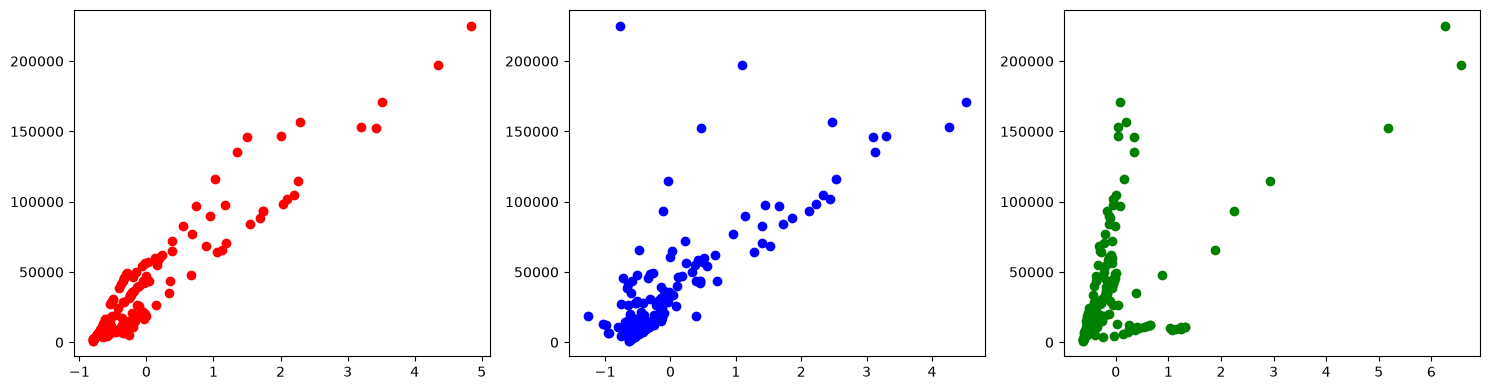

In [89]:
# Ploting scatter

fig, ax = plt.subplots(1,3, figsize=(15, 4))

ax[0].scatter(X_normalized2[:,0],y2, c = 'r')
ax[1].scatter(X_normalized2[:,1],y2, c = 'b')
ax[2].scatter(X_normalized2[:,2],y2, c = 'g')

plt.tight_layout()
plt.show()

In [90]:
#Cost Function
def computeCost(X,y,theta=[[0],[0],[0],[0]]):
    m2 = y.size
    X_e = np.c_[np.ones(m2), X]
    h = X_e.dot(theta)
    J = 1/(2*m2) * np.sum((h-y)**2)
    return(J)

In [91]:
computeCost(X_normalized2, y2)

np.float64(251405696430.0917)

In [92]:
def gradientDescent(X, y, theta=[[0], [0], [0], [0]], alpha=0.01, num_iters=50):
    m = y.size
    X_extend = np.c_[np.ones((m, 1)), X]
    
    theta = np.array(theta, dtype=float).reshape(-1, 1)
    y_reshaped = y.reshape(-1, 1)
    J_history = np.zeros(num_iters)
    
    for i in range(num_iters):
        h = X_extend.dot(theta)
        errors = h - y_reshaped
        theta = theta - (alpha / m) * X_extend.T.dot(errors)
        J_history[i] = (1 / (2 * m)) * np.sum(errors ** 2)
        
    return theta, J_history

In [93]:
theta1, cost1 = gradientDescent(X_normalized2, y2, alpha=0.04)
theta2, cost2 = gradientDescent(X_normalized2, y2, alpha=0.08)
theta3, cost3 = gradientDescent(X_normalized2, y2)

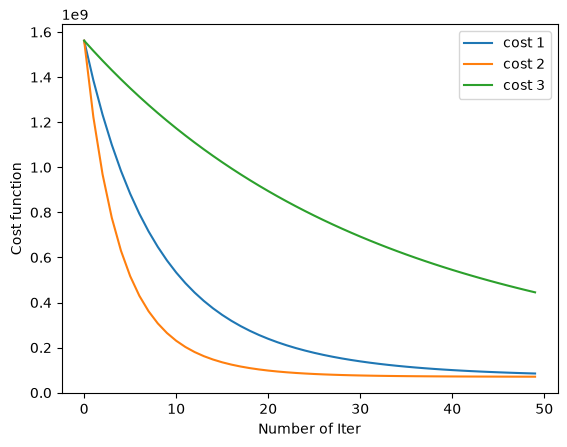

In [94]:
# ploting

plt.plot(cost1,label='cost 1')
plt.plot(cost2,label='cost 2')
plt.plot(cost3,label='cost 3')
plt.xlabel('Number of Iter')
plt.ylabel('Cost function')
plt.legend()

In [95]:
theta1

array([[32527.88235173],
       [20281.71186449],
       [16480.26128609],
       [ 9496.75217257]])

In [96]:
cost1

array([1.56152606e+09, 1.38605467e+09, 1.23338455e+09, 1.10033554e+09,
       9.84191145e+08, 8.82629147e+08, 7.93662837e+08, 7.15591078e+08,
       6.46955941e+08, 5.86506734e+08, 5.33169453e+08, 4.86020827e+08,
       4.44266262e+08, 4.07221087e+08, 3.74294610e+08, 3.44976545e+08,
       3.18825460e+08, 2.95458941e+08, 2.74545205e+08, 2.55795956e+08,
       2.38960282e+08, 2.23819451e+08, 2.10182464e+08, 1.97882247e+08,
       1.86772402e+08, 1.76724416e+08, 1.67625275e+08, 1.59375412e+08,
       1.51886949e+08, 1.45082180e+08, 1.38892269e+08, 1.33256126e+08,
       1.28119442e+08, 1.23433844e+08, 1.19156177e+08, 1.15247873e+08,
       1.11674404e+08, 1.08404812e+08, 1.05411295e+08, 1.02668847e+08,
       1.00154941e+08, 9.78492616e+07, 9.57334558e+07, 9.37909261e+07,
       9.20066429e+07, 9.03669804e+07, 8.88595719e+07, 8.74731816e+07,
       8.61975910e+07, 8.50234978e+07])

In [97]:
# Prediction

new_set = np.array([[365817.0, 94680.0, 154000]])

new_set_norm = (new_set - X_mean_2) / X_std_2
new_set_ext = np.c_[1, new_set_norm]

In [98]:
new_set_ext

array([[1.        , 3.20375636, 4.25702785, 0.03717826]])

In [99]:
prediction = new_set_ext.dot(theta1)
print(prediction)

[[168015.54961696]]


# Logistic regression

In [103]:
dataset2 = data1.iloc[:,]

In [104]:
dataset2.head(10)

,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820,infected
0,948,2,48,89.8128,0,0,0,100,0,0,0,0,0,0,1,0,1,0,422,477,566,324,0
1,1002,3,61,49.4424,0,0,0,90,0,1,895,0,0,1,3,0,1,0,162,218,392,564,1
2,961,3,45,88.4520,0,1,1,90,0,1,707,0,1,1,3,0,1,1,326,274,2063,1893,0
3,1166,3,47,85.2768,0,1,0,100,0,1,1399,0,1,1,3,0,1,0,287,394,1590,966,0
4,1090,0,43,66.6792,0,1,0,100,0,1,1352,0,1,1,3,0,0,0,504,353,870,782,0
5,1181,1,46,88.9056,0,1,1,100,0,1,1181,0,1,1,3,0,1,0,235,339,860,1060,0
6,794,0,31,73.0296,0,1,0,100,0,1,930,0,1,1,3,0,0,0,244,225,708,699,1
7,957,0,41,66.2256,0,1,1,100,0,1,1329,0,1,1,3,0,0,0,401,366,889,720,0
8,198,3,40,82.5552,0,1,0,90,0,1,1074,0,1,1,3,1,1,1,214,107,652,131,1
9,188,0,35,78.0192,0,1,0,100,0,1,964,0,1,1,3,0,0,1,221,132,221,759,1


In [105]:
dataset2 = data1.to_numpy()

In [106]:
# Seting variables
X_inp = dataset2[:, 18:20]
y_inp = dataset2[:,-1]

m = y.size

In [107]:
#normalization

X_inp_norm = (X_inp - np.mean(X_inp, axis=0)) / np.std(X_inp, axis=0)

In [108]:
X_inp_norm

array([[ 0.60313081,  0.73092701],
       [-1.590108  , -1.06020741],
       [-0.20668044, -0.6729351 ],
       ...,
       [ 0.57782421, -0.05053318],
       [-1.55636586, -1.39907067],
       [ 4.72810689,  3.86368335]], shape=(2139, 2))

In [109]:
y_inp

array([0., 1., 0., ..., 0., 1., 0.], shape=(2139,))

In [110]:
X_1 = X_inp_norm[y_inp == 1]
X_0 = X_inp_norm[y_inp == 0]

cd80_1 = X_1[:, 0]
cd820_1 = X_1[:, 1]

cd80_0 = X_0[:, 0]
cd820_0 = X_0[:, 1]

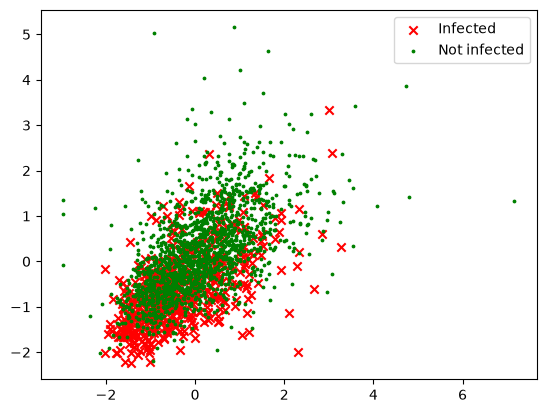

In [111]:
plt.scatter(cd80_1, cd820_1, c='r', marker = 'x', label = 'Infected')
plt.scatter(cd80_0, cd820_0, c='g', s= 3, label = 'Not infected')

plt.legend()
plt.show()

In [112]:
# ------------------ building model------------------

def sigmoid(z):
    sig = 1 / (1 + np.exp(-z))
    return sig

In [113]:
def costFunction(X, y, theta=[[0], [0], [0]]):
    m = y.size
    X_ext = np.c_[np.ones(m), X]
    z = np.dot(X_ext, theta)
    h = sigmoid(z)
    cost = -1/m * np.sum(y * np.log(h) + (1-y) * np.log(1 - h))
    
    return cost

In [114]:
costFunction(X_inp_norm , y_inp)

np.float64(1482.641819217723)

In [115]:
# Gradient Descent

def gradientDescent(X, y, theta=[[0], [0], [0]], alpha = 0.000001, iterations = 1000):
    
    m = y.size
    X_ext = np.c_[np.ones(m), X]


    theta = np.array(theta, dtype=float).reshape(-1, 1)
    y_reshaped = y.reshape(-1, 1)
    
    j_history = []

    disp = iterations//10

    for i in range(iterations):
        
        z = np.dot(X_ext, theta)
        h = sigmoid(z)
        epsilon = 1e-15  
        h = np.clip(h, epsilon, 1 - epsilon)
        
        
        theta = theta - (alpha / m) * X_ext.T.dot(h - y_reshaped)

        j = (-1 / m) * np.sum(y_reshaped * np.log(h) + (1 - y_reshaped) * np.log(1 - h))
        j_history.append(j)
        
        if (i+1) % disp == 0:
            print("Iteration", i+1, " | Cost: ", j, "\n")
    
    return  theta, j_history

In [116]:
theta , j_history = gradientDescent(X_inp , y_inp)

Iteration 100  | Cost:  0.5117407221675278 

Iteration 200  | Cost:  0.5084078915136891 

Iteration 300  | Cost:  0.505711218318409 

Iteration 400  | Cost:  0.503515971094608 

Iteration 500  | Cost:  0.5017252991011639 

Iteration 600  | Cost:  0.5002617621733283 

Iteration 700  | Cost:  0.4990633177659539 

Iteration 800  | Cost:  0.498080153933116 

Iteration 900  | Cost:  0.4972721902851464 

Iteration 1000  | Cost:  0.49660710437627226 



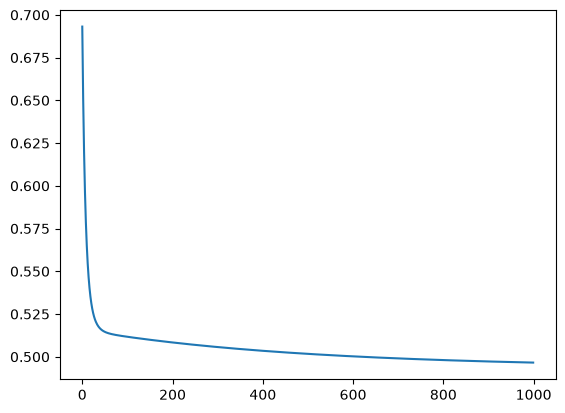

In [117]:
plt.plot(j_history)

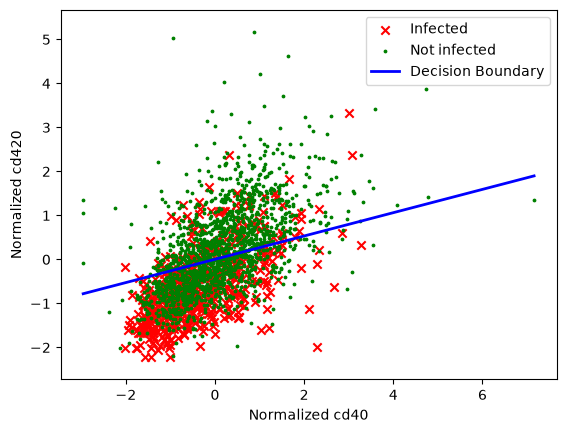

In [118]:
# Create a smooth range of x1 (normalized cd80) values
x1_vals = np.linspace(X_inp_norm[:, 0].min(), X_inp_norm[:, 0].max(), 100)

# Calculate corresponding x2 (normalized cd820) values along the decision boundary (z = 0)
x2_vals = -(1/theta[2]) * (theta[0] + theta[1] * x1_vals)

# Plot data points and the decision boundary
plt.scatter(cd80_1, cd820_1, c='r', marker='x', label='Infected')
plt.scatter(cd80_0, cd820_0, c='g', s=3, label='Not infected')
plt.plot(x1_vals, x2_vals, c='blue', linewidth=2, label='Decision Boundary')

plt.xlabel('Normalized cd40')
plt.ylabel('Normalized cd420')
plt.ylim(X_inp_norm[:, 1].min() - 0.5, X_inp_norm[:, 1].max() + 0.5)
plt.legend()
plt.show()

In [119]:
def predict(X, theta):
    X_norm = (X - np.mean(X_inp, axis=0)) / np.std(X_inp, axis=0)
    X_ext = np.c_[np.ones((X_norm.shape[0], 1)), X_norm]
    prob = sigmoid(np.dot(X_ext, theta))
    return (prob >= 0.5).astype(int)

predict(np.array([[214, 107]]), theta)

array([[1]])